## cartesian-to-ternary illustration
Generates supplementary figure B6

In [46]:
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d import proj3d
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Ensure scikit-bio is installed: pip install scikit-bio
from skbio.stats.composition import clr, clr_inv, ilr

In [47]:
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [48]:
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

# Figure 1

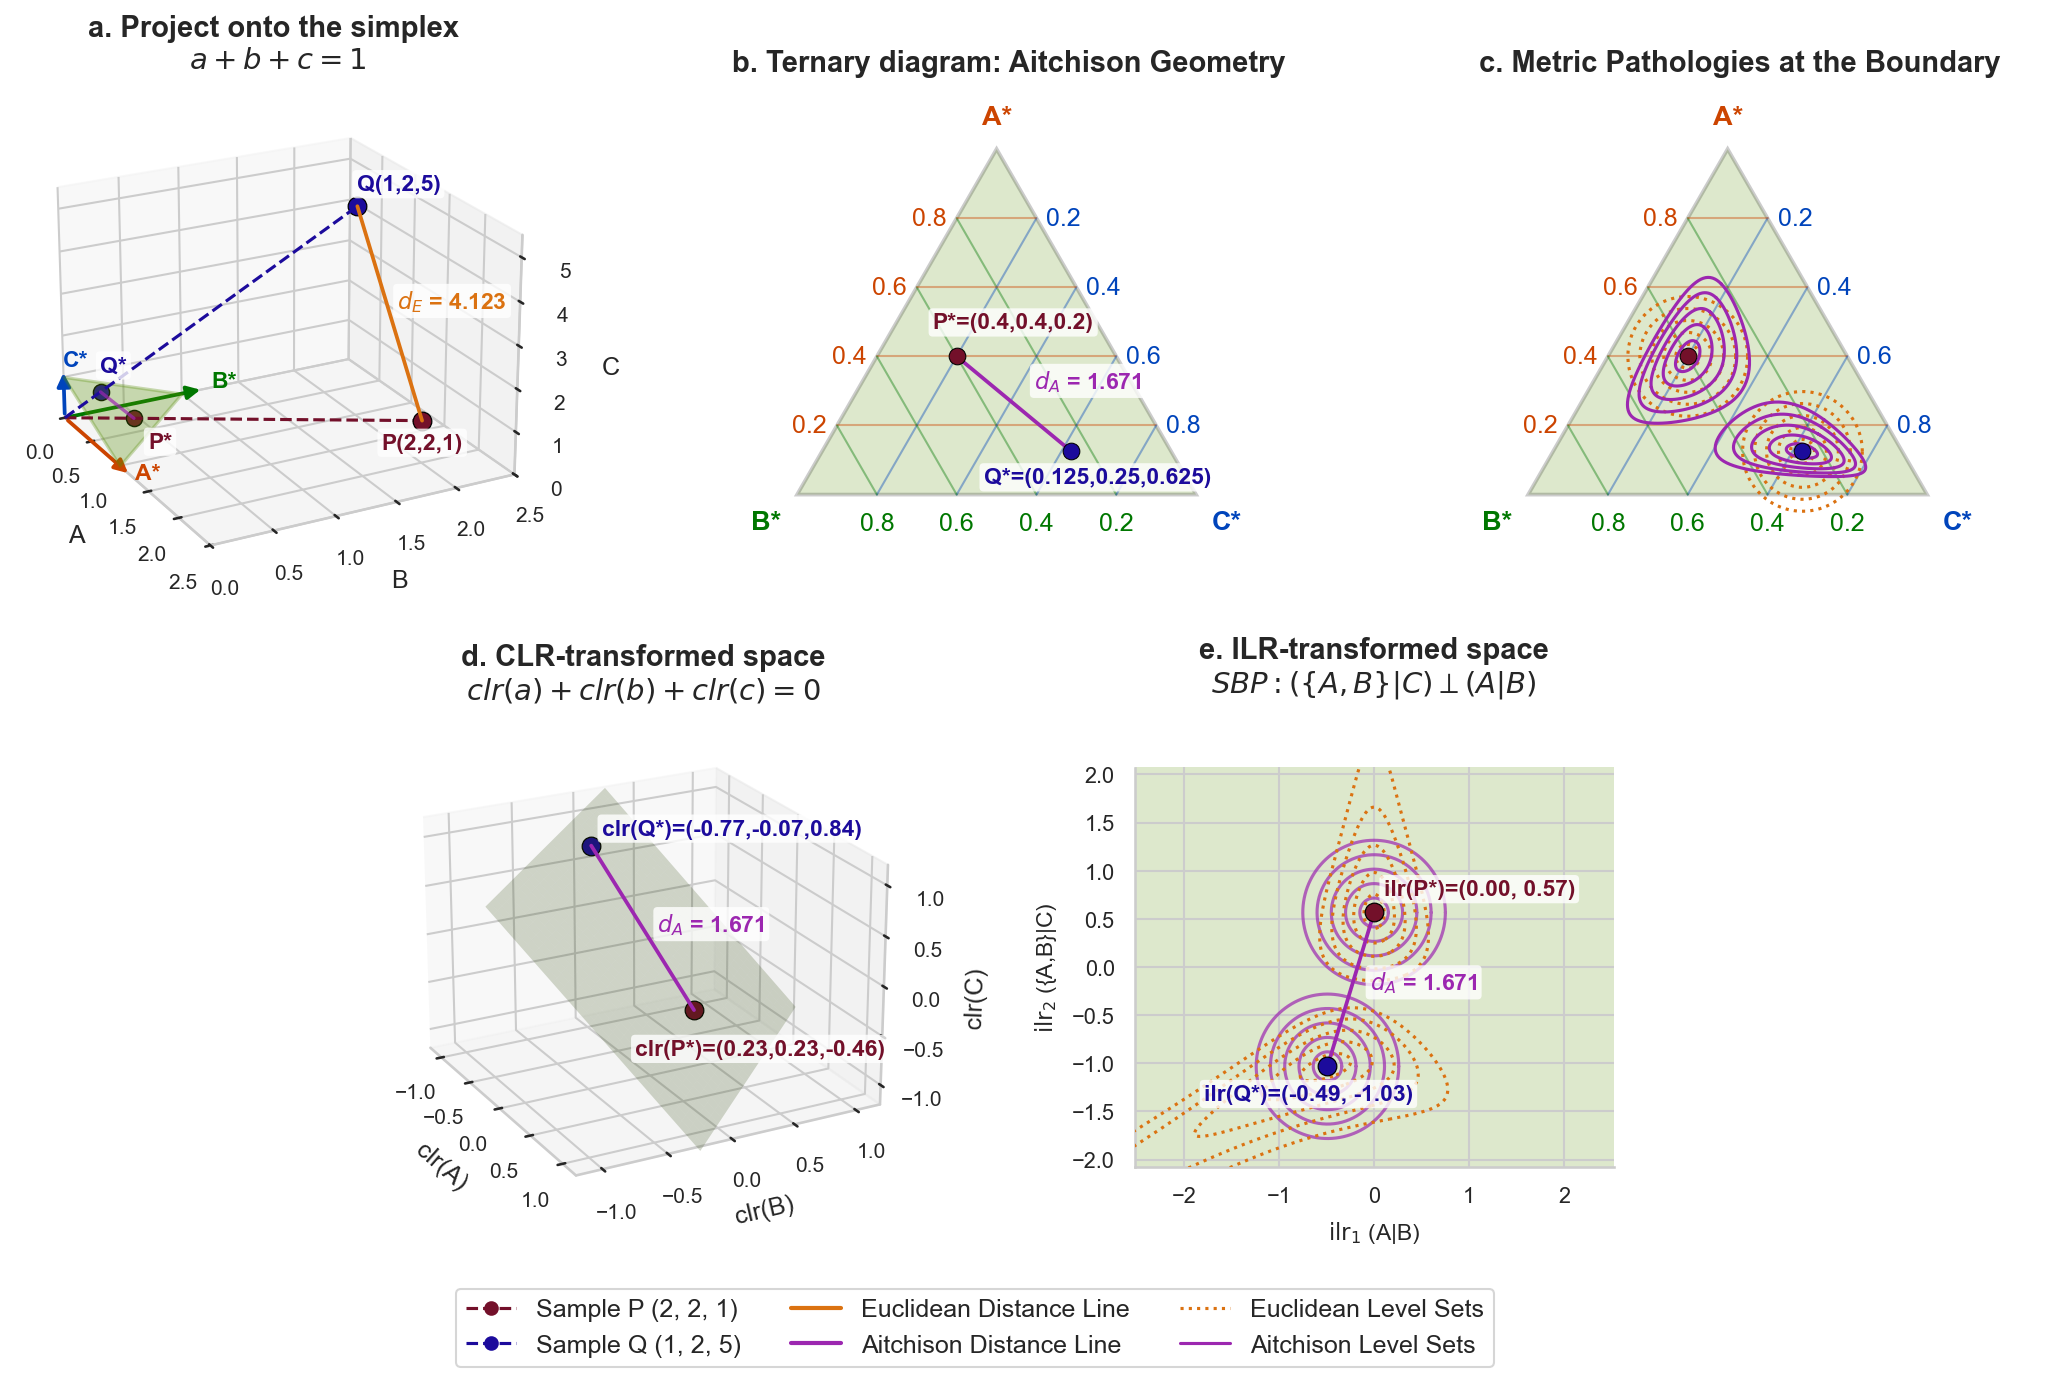

In [ ]:
sns.set_theme(style='whitegrid', font_scale=0.95)

# ── 3D Arrow Helper ───────────────────────────────────────────────────────────
class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        return min(zs)

# ── helper functions ─────────────────────────────────────────────────────────
def _clr_local(v):
    v = np.asarray(v, float)
    return np.log(v) - np.mean(np.log(v))

def draw_point_box(ax, x, y, z, color, lw=0.7, edge_alpha=0.45, face_alpha=0.07):
    edges = [
        [(x,0,0),(x,y,0)], [(0,y,0),(x,y,0)], [(0,0,z),(x,0,z)], [(0,0,z),(0,y,z)],
        [(x,0,z),(x,y,z)], [(0,y,z),(x,y,z)], [(x,0,0),(x,0,z)], [(0,y,0),(0,y,z)],
        [(x,y,0),(x,y,z)],
    ]
    for (x0,y0,z0),(x1,y1,z1) in edges:
        ax.plot([x0,x1],[y0,y1],[z0,z1], color=color, lw=lw, alpha=edge_alpha, ls=':', zorder=2)
    faces = [
        [(0,0,0),(x,0,0),(x,y,0),(0,y,0)], [(0,0,z),(x,0,z),(x,y,z),(0,y,z)],
        [(0,y,0),(x,y,0),(x,y,z),(0,y,z)], [(0,0,0),(x,0,0),(x,0,z),(0,0,z)],
        [(0,0,0),(0,y,0),(0,y,z),(0,0,z)], [(x,0,0),(x,y,0),(x,y,z),(x,0,z)],
    ]
    poly = Poly3DCollection(faces, alpha=face_alpha, facecolor=color, edgecolor='none', zorder=1)
    ax.add_collection3d(poly)

def get_clr_ring_ternary(center_comp, radius, n_points=100):
    t = np.linspace(0, 2*np.pi, n_points)
    v1 = np.array([1, -1, 0]) / np.sqrt(2)
    v2 = np.array([1, 1, -2]) / np.sqrt(6)
    center_clr = clr(center_comp)
    ring_points_clr = []
    for angle in t:
        p_clr = center_clr + radius * (np.cos(angle) * v1 + np.sin(angle) * v2)
        ring_points_clr.append(clr_inv(p_clr))
    return np.array(ring_points_clr)

# ── reusable style: white background so labels stay readable over lines/points ─
_LBL = dict(
    bbox=dict(boxstyle='round,pad=0.18', facecolor='white', alpha=0.80, edgecolor='none'),
    zorder=20
)

# ── data for all panels ──────────────────────────────────────────────────────
a, b, c = 2, 2, 1
q, r, s = 1, 2, 5
a_close, b_close, c_close = a/(a+b+c), b/(a+b+c), c/(a+b+c)
q_close, r_close, s_close = q/(q+r+s), r/(q+r+s), s/(q+r+s)

d_E = float(np.linalg.norm([a - q, b - r, c - s]))
d_A = float(np.linalg.norm(_clr_local([a, b, c]) - _clr_local([q, r, s])))

clr_P = _clr_local([a_close, b_close, c_close])
clr_Q = _clr_local([q_close, r_close, s_close])

ilr_P = ilr(np.array([[a_close, b_close, c_close]]))[0]
ilr_Q = ilr(np.array([[q_close, r_close, s_close]]))[0]

# Shared level-set radii (same across panels C, D, E)
radii_eucl = [0.03, 0.06, 0.09, 0.12, 0.15]
radii_clr  = [0.15, 0.3, 0.45, 0.6, 0.75]

# ── figure layout ─────────────────────────────────────────────────────────────
# Row 0: a=[0,0:2], b=[0,2:4], c=[0,4:6]  — three equal thirds
# Row 1: d=[1,0:3], e=[1,3:6]             — two equal halves (fills full width)
fig = plt.figure(figsize=(18, 10), dpi=150, facecolor='white')
gs  = gridspec.GridSpec(2, 6, figure=fig, wspace=0.38, hspace=0.2)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL A — row 0, cols 0-1
# ═════════════════════════════════════════════════════════════════════════════
ax1 = fig.add_subplot(gs[0, 0:2], projection='3d')

V = np.array([[1,0,0],[0,1,0],[0,0,1]], float)
ax1.add_collection3d(Poly3DCollection([V.tolist()], alpha=0.30,
                                       facecolor=OLIVE, edgecolor=OLIVE, linewidths=1.5))

AX_MAX2 = 1.2; AX2_MAX1 = 5; AX2_MAX2 = 2
for xs, ys, zs, col, lbl, tp in [
    ([0, AX_MAX2], [0, 0],       [0, 0],       A_COLOR, 'A*', (AX_MAX2+0.06, 0, 0)),
    ([0, 0],       [0, AX_MAX2], [0, 0],       B_COLOR, 'B*', (0, AX_MAX2+0.06, 0)),
    ([0, 0],       [0, 0],       [0, AX_MAX2], C_COLOR, 'C*', (0, 0, AX_MAX2+0.06)),
]:
    arr = Arrow3D(xs, ys, zs, arrowstyle="-|>", mutation_scale=13, lw=1.8, color=col, zorder=3)
    ax1.add_artist(arr)
    ax1.text(*tp, lbl, fontsize=11, fontweight='bold', color=col)

ax1.plot([0, a],[0, b],[0, c], color=CRIMSON, lw=1.5, ls='--', zorder=5)
ax1.plot([0, q],[0, r],[0, s], color=INDIGO,  lw=1.5, ls='--', zorder=5)
ax1.scatter([a],[b],[c], color=CRIMSON, s=80, zorder=10, edgecolors='black', linewidths=0.6)
ax1.text(a+0.1, b-0.4, c-0.3, f'P({a},{b},{c})', fontsize=11, fontweight='bold', color=CRIMSON, **_LBL)
ax1.scatter([q],[r],[s], color=INDIGO, s=80, zorder=10, edgecolors='black', linewidths=0.6)
ax1.text(q+0.02, r-0.02, s+0.4, f'Q({q},{r},{s})', fontsize=11, fontweight='bold', color=INDIGO, **_LBL)

ax1.plot([a_close,q_close],[b_close,r_close],[c_close,s_close], color=DIST_A, lw=1.6, zorder=6, alpha=0.7)
ax1.scatter([a_close],[b_close],[c_close], color=CRIMSON, s=60, zorder=11, edgecolors='black', linewidths=0.7)
ax1.text(a_close+0.2, b_close+0.02, c_close-0.5, 'P*', fontsize=11, fontweight='bold', color=CRIMSON, **_LBL)
ax1.plot([a,q],[b,r],[c,s], color=DIST_E, lw=1.8, zorder=6)
mx, my, mz = (a+q)/2, (b+r)/2, (c+s)/2
ax1.text(mx-0.04, my+0.09, mz+0.02, f'$d_E$ = {d_E:.3f}', fontsize=11, color=DIST_E, fontweight='bold', **_LBL)
ax1.scatter([q_close],[r_close],[s_close], color=INDIGO, s=60, zorder=11, edgecolors='black', linewidths=0.7)
ax1.text(q_close, r_close, s_close+0.5, 'Q*', fontsize=11, fontweight='bold', color=INDIGO, **_LBL)

ax1.set_xlim(0, AX2_MAX2+0.5); ax1.set_ylim(0, AX2_MAX2+0.5); ax1.set_zlim(0, AX2_MAX1+0.5)
ax1.set_xlabel('A', fontsize=12); ax1.set_ylabel('B', fontsize=12); ax1.set_zlabel('C', fontsize=12)
ax1.tick_params(labelsize=10)
ax1.set_title('a. Project onto the simplex \n$a + b + c = 1$', fontsize=14, fontweight='bold', pad=2)
ax1.view_init(elev=22, azim=-28)

# ═════════════════════════════════════════════════════════════════════════════
# COMMON TERNARY LOGIC
# ═════════════════════════════════════════════════════════════════════════════
TA = np.array([0.5, np.sqrt(3)/2])
TB = np.array([0.0, 0.0])
TC = np.array([1.0, 0.0])

def t2d(p_, q_, r_):
    return p_*TA + q_*TB + r_*TC

def t2d_inv(x, y):
    """Ternary 2D → (p, q, r) on the simplex."""
    p = 2 * y / np.sqrt(3)
    r = x - y / np.sqrt(3)
    q = 1 - p - r
    return np.array([p, q, r])

def draw_ternary_base(ax, title):
    ax.set_aspect('equal'); ax.set_axis_off()
    tri_patch = plt.Polygon([TA, TB, TC], facecolor=OLIVE, edgecolor='black', lw=1.8, alpha=0.2, zorder=1)
    ax.add_patch(tri_patch)
    for v in [0.2, 0.4, 0.6, 0.8]:
        p1, p2 = t2d(v, 1-v, 0), t2d(v, 0, 1-v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=A_COLOR, lw=1, alpha=0.4, zorder=2)
        p1, p2 = t2d(1-v, v, 0), t2d(0, v, 1-v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=B_COLOR, lw=1, alpha=0.4, zorder=2)
        p1, p2 = t2d(1-v, 0, v), t2d(0, 1-v, v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=C_COLOR, lw=1, alpha=0.4, zorder=2)
        pt_A = t2d(v, 1-v, 0)
        ax.text(pt_A[0]-0.025, pt_A[1], f'{v}', fontsize=12, color=A_COLOR, ha='right', va='center')
        pt_B = t2d(0, v, 1-v)
        ax.text(pt_B[0], pt_B[1]-0.045, f'{v}', fontsize=12, color=B_COLOR, ha='center', va='top')
        pt_C = t2d(v, 0, 1-v)
        ax.text(pt_C[0]+0.025, pt_C[1], f'{round(1-v,1)}', fontsize=12, color=C_COLOR, ha='left', va='center')
    ax.text(TA[0], TA[1]+0.05, 'A*', fontsize=13, fontweight='bold', color=A_COLOR, ha='center', va='bottom')
    ax.text(TB[0]-0.04, TB[1]-0.04, 'B*', fontsize=13, fontweight='bold', color=B_COLOR, ha='right', va='top')
    ax.text(TC[0]+0.04, TC[1]-0.04, 'C*', fontsize=13, fontweight='bold', color=C_COLOR, ha='left', va='top')
    ax.set_xlim(-0.26, 1.32); ax.set_ylim(-0.26, 1.05)
    ax.set_title(title, fontsize=14, fontweight='bold', pad=2)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL B — row 0, cols 2-3
# ═════════════════════════════════════════════════════════════════════════════
ax2 = fig.add_subplot(gs[0, 2:4])
draw_ternary_base(ax2, 'b. Ternary diagram: Aitchison Geometry')

P2 = t2d(a_close, b_close, c_close)
Q2 = t2d(q_close, r_close, s_close)

ax2.plot(*P2, 'o', color=CRIMSON, markersize=8, markeredgecolor='black', markeredgewidth=0.5, zorder=10)
ax2.text(P2[0]-0.06, P2[1]+0.07, f"P*=({a_close},{b_close},{c_close})",
         fontsize=11, fontweight='bold', color=CRIMSON, **_LBL)
ax2.plot(*Q2, 'o', color=INDIGO, markersize=8, markeredgecolor='black', markeredgewidth=0.5, zorder=10)
ax2.text(Q2[0]-0.22, Q2[1]-0.08, f"Q*=({q_close},{r_close},{s_close})",
         fontsize=11, fontweight='bold', color=INDIGO, **_LBL)

ax2.plot([P2[0], Q2[0]], [P2[1], Q2[1]], color=DIST_A, lw=1.8, zorder=6)
mx2 = (P2[0] + Q2[0]) / 2; my2 = (P2[1] + Q2[1]) / 2
ax2.text(mx2 + 0.05, my2 + 0.04, f'$d_A$ = {d_A:.3f}',
         fontsize=11, color=DIST_A, fontweight='bold', **_LBL)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL C — row 0, cols 4-5
# ═════════════════════════════════════════════════════════════════════════════
ax3 = fig.add_subplot(gs[0, 4:6])
draw_ternary_base(ax3, 'c. Metric Pathologies at the Boundary')

points_d  = [a_close, b_close, c_close], [q_close, r_close, s_close]
colors_d  = [CRIMSON, INDIGO]

for pi, p in enumerate(points_d):
    cx, cy = t2d(p[0], p[1], p[2])
    t_ang = np.linspace(0, 2*np.pi, 100)
    for ra in radii_eucl:
        ax3.plot(cx + ra*np.cos(t_ang), cy + ra*np.sin(t_ang),
                 color=DIST_E, lw=1.5, ls=':', zorder=4)
    for ra in radii_clr:
        ring = get_clr_ring_ternary(p, ra)
        x_clr = [t2d(tp[0], tp[1], tp[2])[0] for tp in ring]
        y_clr = [t2d(tp[0], tp[1], tp[2])[1] for tp in ring]
        x_clr.append(x_clr[0]); y_clr.append(y_clr[0])
        ax3.plot(x_clr, y_clr, color=DIST_A, lw=1.5, ls='-', zorder=5)
    ax3.plot([cx], [cy], marker='o', markersize=8, color=colors_d[pi],
             markeredgecolor='black', markeredgewidth=0.5, zorder=6)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL D — row 1, cols 0-2: CLR-transformed space
# ═════════════════════════════════════════════════════════════════════════════
ax_c = fig.add_subplot(gs[1, 1:3], projection='3d')

CLR_AX_MAX = 1.0

_v1 = np.array([1, -1,  0]) / np.sqrt(2)
_v2 = np.array([1,  1, -2]) / np.sqrt(6)

_ss, _tt = np.linspace(-1.3, 1.3, 30), np.linspace(-1.3, 1.3, 30)
_SS, _TT = np.meshgrid(_ss, _tt)
_XP = _SS * _v1[0] + _TT * _v2[0]
_YP = _SS * _v1[1] + _TT * _v2[1]
_ZP = _SS * _v1[2] + _TT * _v2[2]
ax_c.plot_surface(_XP, _YP, _ZP, alpha=0.2, color=OLIVE, zorder=1, linewidth=0)

ax_c.scatter([clr_P[0]], [clr_P[1]], [clr_P[2]], color=CRIMSON, s=80, zorder=10,
             edgecolors='black', linewidths=0.6)
ax_c.text(clr_P[0]+0.05, clr_P[1]-0.50, clr_P[2]-0.30,
          f'clr(P*)=({clr_P[0]:.2f},{clr_P[1]:.2f},{clr_P[2]:.2f})',
          fontsize=11, fontweight='bold', color=CRIMSON, **_LBL)

ax_c.scatter([clr_Q[0]], [clr_Q[1]], [clr_Q[2]], color=INDIGO, s=80, zorder=10,
             edgecolors='black', linewidths=0.6)
ax_c.text(clr_Q[0]+0.05, clr_Q[1]+0.06, clr_Q[2]+0.12,
          f'clr(Q*)=({clr_Q[0]:.2f},{clr_Q[1]:.2f},{clr_Q[2]:.2f})',
          fontsize=11, fontweight='bold', color=INDIGO, **_LBL)

ax_c.plot([clr_P[0], clr_Q[0]], [clr_P[1], clr_Q[1]], [clr_P[2], clr_Q[2]],
          color=DIST_A, lw=1.8, zorder=6)
mx_c = (clr_P[0]+clr_Q[0])/2; my_c = (clr_P[1]+clr_Q[1])/2; mz_c = (clr_P[2]+clr_Q[2])/2
ax_c.text(mx_c+0.12, my_c+0.06, mz_c, f'$d_A$ = {d_A:.3f}',
          fontsize=11, color=DIST_A, fontweight='bold', **_LBL)

ax_c.set_xlim(-1.2, 1.2); ax_c.set_ylim(-1.2, 1.2); ax_c.set_zlim(-1.2, 1.2)
ax_c.set_xlabel('clr(A)', fontsize=12); ax_c.set_ylabel('clr(B)', fontsize=12); ax_c.set_zlabel('clr(C)', fontsize=12)
ax_c.tick_params(labelsize=10)
ax_c.set_title('d. CLR-transformed space\n$clr(a)+clr(b)+clr(c)=0$',
               fontsize=14, fontweight='bold', pad=2)
ax_c.view_init(elev=22, azim=-28)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL E — row 1, cols 3-5: ILR-transformed space
# ═════════════════════════════════════════════════════════════════════════════
ax_e = fig.add_subplot(gs[1, 3:5])

ILR_PAD = 0.35
ILR_XLIM = max(abs(ilr_P[0]), abs(ilr_Q[0])) + ILR_PAD
ILR_YLIM = max(abs(ilr_P[1]), abs(ilr_Q[1])) + ILR_PAD

import matplotlib.colors as mcolors

_r, _g, _b, _ = mcolors.to_rgba(OLIVE)
ax_e.set_facecolor((_r, _g, _b, 0.20))

_t_ang = np.linspace(0, 2 * np.pi, 360)

for _p_s, _p_ilr_c in [([a_close, b_close, c_close], ilr_P),
                        ([q_close, r_close, s_close], ilr_Q)]:
    _cx, _cy = t2d(_p_s[0], _p_s[1], _p_s[2])

    for _ra in radii_clr:
        ax_e.plot(_p_ilr_c[0] + _ra * np.cos(_t_ang),
                  _p_ilr_c[1] + _ra * np.sin(_t_ang),
                  color=DIST_A, lw=1.5, ls='-', zorder=3, alpha=0.7)

    for _ra in radii_eucl:
        _xs_t = _cx + _ra * np.cos(_t_ang)
        _ys_t = _cy + _ra * np.sin(_t_ang)
        _seg_x, _seg_y = [], []
        for _xi, _yi in zip(_xs_t, _ys_t):
            _comp = t2d_inv(_xi, _yi)
            if np.all(_comp > 1e-10):
                _pt = ilr(_comp.reshape(1, -1))[0]
                _seg_x.append(_pt[0]); _seg_y.append(_pt[1])
            else:
                if len(_seg_x) > 1:
                    ax_e.plot(_seg_x, _seg_y, color=DIST_E, lw=1.5, ls=':', zorder=4)
                _seg_x, _seg_y = [], []
        if len(_seg_x) > 1:
            ax_e.plot(_seg_x, _seg_y, color=DIST_E, lw=1.5, ls=':', zorder=4)

ax_e.scatter([ilr_P[0]], [ilr_P[1]], color=CRIMSON, s=80, zorder=10,
             edgecolors='black', linewidths=0.6)
ax_e.text(ilr_P[0] + 0.1, ilr_P[1] + 0.18,
          f'ilr(P*)=({ilr_P[0]:.2f}, {ilr_P[1]:.2f})',
          fontsize=11, fontweight='bold', color=CRIMSON, **_LBL)

ax_e.scatter([ilr_Q[0]], [ilr_Q[1]], color=INDIGO, s=80, zorder=10,
             edgecolors='black', linewidths=0.6)
ax_e.text(ilr_Q[0] + 0.9, ilr_Q[1] - 0.35,
          f'ilr(Q*)=({ilr_Q[0]:.2f}, {ilr_Q[1]:.2f})',
          fontsize=11, fontweight='bold', color=INDIGO, ha='right', **_LBL)

ax_e.plot([ilr_P[0], ilr_Q[0]], [ilr_P[1], ilr_Q[1]], color=DIST_A, lw=1.8, zorder=7)
mx_e = (ilr_P[0] + ilr_Q[0]) / 2; my_e = (ilr_P[1] + ilr_Q[1]) / 2
ax_e.text(mx_e + 0.2, my_e, f'$d_A$ = {d_A:.3f}',
          fontsize=11, color=DIST_A, fontweight='bold', **_LBL)

ax_e.set_xlim(-ILR_XLIM * 3, ILR_XLIM * 3)
ax_e.set_ylim(-ILR_YLIM * 1.5, ILR_YLIM * 1.5)
ax_e.set_xlabel('$\\mathrm{ilr}_1$ (A|B)', fontsize=11, labelpad=6)
ax_e.set_ylabel('$\\mathrm{ilr}_2$ ({A,B}|C)', fontsize=11, labelpad=6)
for spine in ['top', 'right']:
    ax_e.spines[spine].set_visible(False)
    
# 1. Get the current bounding box of the subplot
box = ax_e.get_position()

# 2. Define the padding for EACH side (e.g., 10% of the current size)
pad_x = box.width * 0.12
pad_y = box.height * 0.12

# 3. Calculate the new position. 
# Shift right/up, and subtract TWICE the padding to shrink from all sides.
new_x0 = box.x0 + pad_x
new_y0 = box.y0 + pad_y
new_width = box.width - (2 * pad_x)
new_height = box.height - (2 * pad_y)

# 4. Apply the new, centered bounding box
ax_e.set_position([new_x0, new_y0, new_width, new_height])

# 5. Set the title and push it back up to its original spot
# Since the top edge moved down by `pad_y`, we offset the title upwards 
# relative to the new, smaller height.
title_shift = pad_y / new_height
ax_e.set_title('e. ILR-transformed space\n$SBP: (\{A,B\}|C) \perp (A|B)$',
               fontsize=14, fontweight='bold', y=1.0 + title_shift)

# ── Global Title and Legend ──────────────────────────────────────────────────
legend_elements = [
    Line2D([0],[0], color=CRIMSON, marker='o', ls='--', markersize=6, label=f'Sample P ({a}, {b}, {c})'),
    Line2D([0],[0], color=INDIGO,  marker='o', ls='--', markersize=6, label=f'Sample Q ({q}, {r}, {s})'),
    Line2D([0],[0], color=DIST_E,  lw=2, ls='-',  label='Euclidean Distance Line'),
    Line2D([0],[0], color=DIST_A,  lw=2, ls='-',  label='Aitchison Distance Line'),
    Line2D([0],[0], color=DIST_E,  lw=1.5, ls=':', label='Euclidean Level Sets'),
    Line2D([0],[0], color=DIST_A,  lw=1.5, ls='-', label='Aitchison Level Sets'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, 0.01), fontsize=12, frameon=True, edgecolor='#cccccc')

for ax in [ax1, ax_c, ax2, ax3]:
    ax.title.set_y(1.5)

plt.savefig(PLOT_DIR / 'b6_cartesian_to_ternary_combined.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.savefig(PLOT_DIR / 'b6_cartesian_to_ternary_combined.svg', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()